# Lab 12 - Train and Evaluate a Pedestrian Detector

In this lab, you will fine-tune a small pretrained YOLO detector on the prepared pedestrian dataset, inspect its evaluation results, and test it on unseen images.

## Objectives

- Reuse the verified dataset from Lab 11 or prepare it again after a runtime reset.
- Fine-tune a pretrained detector with a GPU.
- Read mAP at IoU 0.50 and mAP across IoU thresholds.
- Inspect predictions on held-out test images.
- Test the trained detector on one new image or short video.

## GPU runtime

Training requires a GPU runtime. In Google Colab, select **Runtime → Change runtime type → T4 GPU** before running the training cell.

In [13]:
%pip -q install "numpy==2.1.3" "albumentations>=1.4.24" "ultralytics>=8.3.0"

In [14]:
from pathlib import Path
Path('/content/README.md').touch()

In [15]:
!ls /content/

detection_dataset.py  __pycache__  README.md  sample_data  work


In [16]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

lab_candidates = [
    Path.cwd(),
    Path.cwd() / 'Lab12',
    Path.cwd() / 'Labs' / 'Obj_detection' / 'Lab12',
    Path('/content/Obj_detection/Lab12'),
    Path('/content/Lab12'),
]
for lab_root in lab_candidates:
    if (lab_root / 'README.md').exists() and (lab_root / 'detection_dataset.py').exists():
        break
else:
    raise FileNotFoundError('Keep all Lab12 files in the same folder.')

if str(lab_root) not in sys.path:
    sys.path.insert(0, str(lab_root))

import detection_dataset as dd
importlib.reload(dd)

workspace = lab_root / 'work'
workspace.mkdir(exist_ok=True)

## 1. Load the prepared dataset

The cell first looks for the augmented dataset created in Lab 11. If it is unavailable, it rebuilds the same fixed split and augmentation locally.

In [17]:
lab11_dataset_root = lab_root.parent / 'Lab11' / 'work' / 'pennfudan_yolo_augmented'
if (lab11_dataset_root / 'data.yaml').exists():
    dataset_root = lab11_dataset_root
    print('Using the augmented dataset from Lab 11.')
else:
    source_root = dd.download_pennfudan(workspace / 'source')
    base_dataset_root = dd.prepare_base_dataset(
        source_root, workspace / 'pennfudan_yolo', seed=2026
    )
    dataset_root = dd.make_augmented_dataset(
        base_dataset_root, workspace / 'pennfudan_yolo_augmented', seed=2026
    )
    print('Prepared a local copy of the dataset.')

data_yaml = dd.write_dataset_yaml(dataset_root)
dataset_summary = dd.validate_yolo_dataset(dataset_root)
for split, counts in dataset_summary.items():
    print(f"{split}: {counts['images']} images, {counts['boxes']} boxes")
print('Data configuration:', data_yaml)

Prepared a local copy of the dataset.
train: 119 images, 291 boxes
val: 26 images, 68 boxes
test: 25 images, 64 boxes
Data configuration: /content/work/pennfudan_yolo_augmented/data.yaml


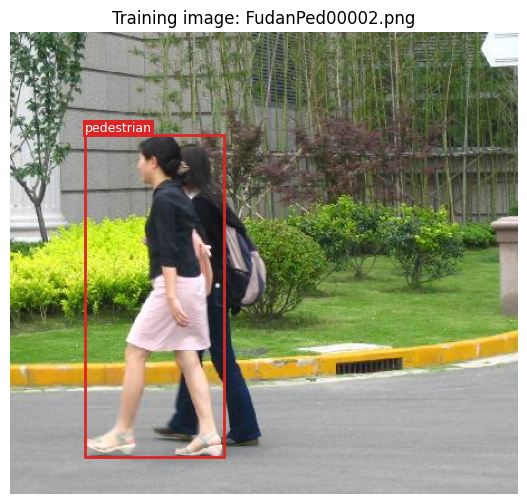

In [18]:
image_array, class_ids, boxes, image_path = dd.load_yolo_sample(dataset_root, 'train', index=0)
figure, axes = plt.subplots(figsize=(7, 6))
dd.plot_yolo_sample(axes, image_array, class_ids, boxes)
axes.set_title(f'Training image: {image_path.name}')
plt.show()

## 2. Check the runtime

The training run uses a small pretrained YOLO model. The explicit augmentations from Lab 11 are already in the training split, so the training cell disables additional random image transformations.

In [19]:
if not torch.cuda.is_available():
    raise RuntimeError('No GPU was detected. Enable a GPU runtime, then run this notebook again.')

print('GPU:', torch.cuda.get_device_name(0))
print('CUDA version:', torch.version.cuda)

GPU: Tesla T4
CUDA version: 13.0


## 3. Fine-tune the detector

The pretrained model already recognizes common visual features. Fine-tuning adapts it to the pedestrian labels and image style in this dataset.

In [20]:
from ultralytics import YOLO

run_root = workspace / 'runs'
run_name = 'pedestrian_yolo11n'
model = YOLO('yolo11n.pt')
training_result = model.train(
    data=str(data_yaml),
    epochs=10,
    imgsz=512,
    batch=16,
    device=0,
    workers=2,
    seed=2026,
    deterministic=True,
    project=str(run_root),
    name=run_name,
    exist_ok=True,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.0,
    mosaic=0.0,
    mixup=0.0,
    verbose=True,
)

run_dir = run_root / run_name
best_weights = run_dir / 'weights' / 'best.pt'
if not best_weights.exists():
    raise FileNotFoundError(f'Could not find trained weights at {best_weights}')
print('Best weights:', best_weights)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/pennfudan_yolo_augmented/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscri

## 4. Evaluate the trained model

mAP at IoU 0.50 counts a prediction as correct with a looser overlap requirement. mAP from 0.50 to 0.95 is stricter because it averages results over several overlap thresholds.

In [21]:
best_model = YOLO(best_weights)
validation_metrics = best_model.val(
    data=str(data_yaml),
    split='val',
    imgsz=512,
    batch=16,
    device=0,
    plots=True,
    project=str(run_root),
    name=f'{run_name}_validation',
    exist_ok=True,
)
test_metrics = best_model.val(
    data=str(data_yaml),
    split='test',
    imgsz=512,
    batch=16,
    device=0,
    plots=True,
    project=str(run_root),
    name=f'{run_name}_test',
    exist_ok=True,
)

print(f"Validation mAP@0.50: {validation_metrics.box.map50:.4f}")
print(f"Validation mAP@0.50:0.95: {validation_metrics.box.map:.4f}")
print(f"Test mAP@0.50: {test_metrics.box.map50:.4f}")
print(f"Test mAP@0.50:0.95: {test_metrics.box.map:.4f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3388.7±519.7 MB/s, size: 282.4 KB)
val: Scanning /content/work/pennfudan_yolo_augmented/val/labels.cache... 26 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 9.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.0it/s 1.0s
                   all         26         68      0.868      0.794      0.884      0.622
Speed: 2.6ms preprocess, 7.1ms inference, 0.0ms loss, 5.0ms postprocess per image
Results saved to /content/work/runs/pedestrian_yolo11n_validation
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2930.2±474.5 MB/s, si

results.png


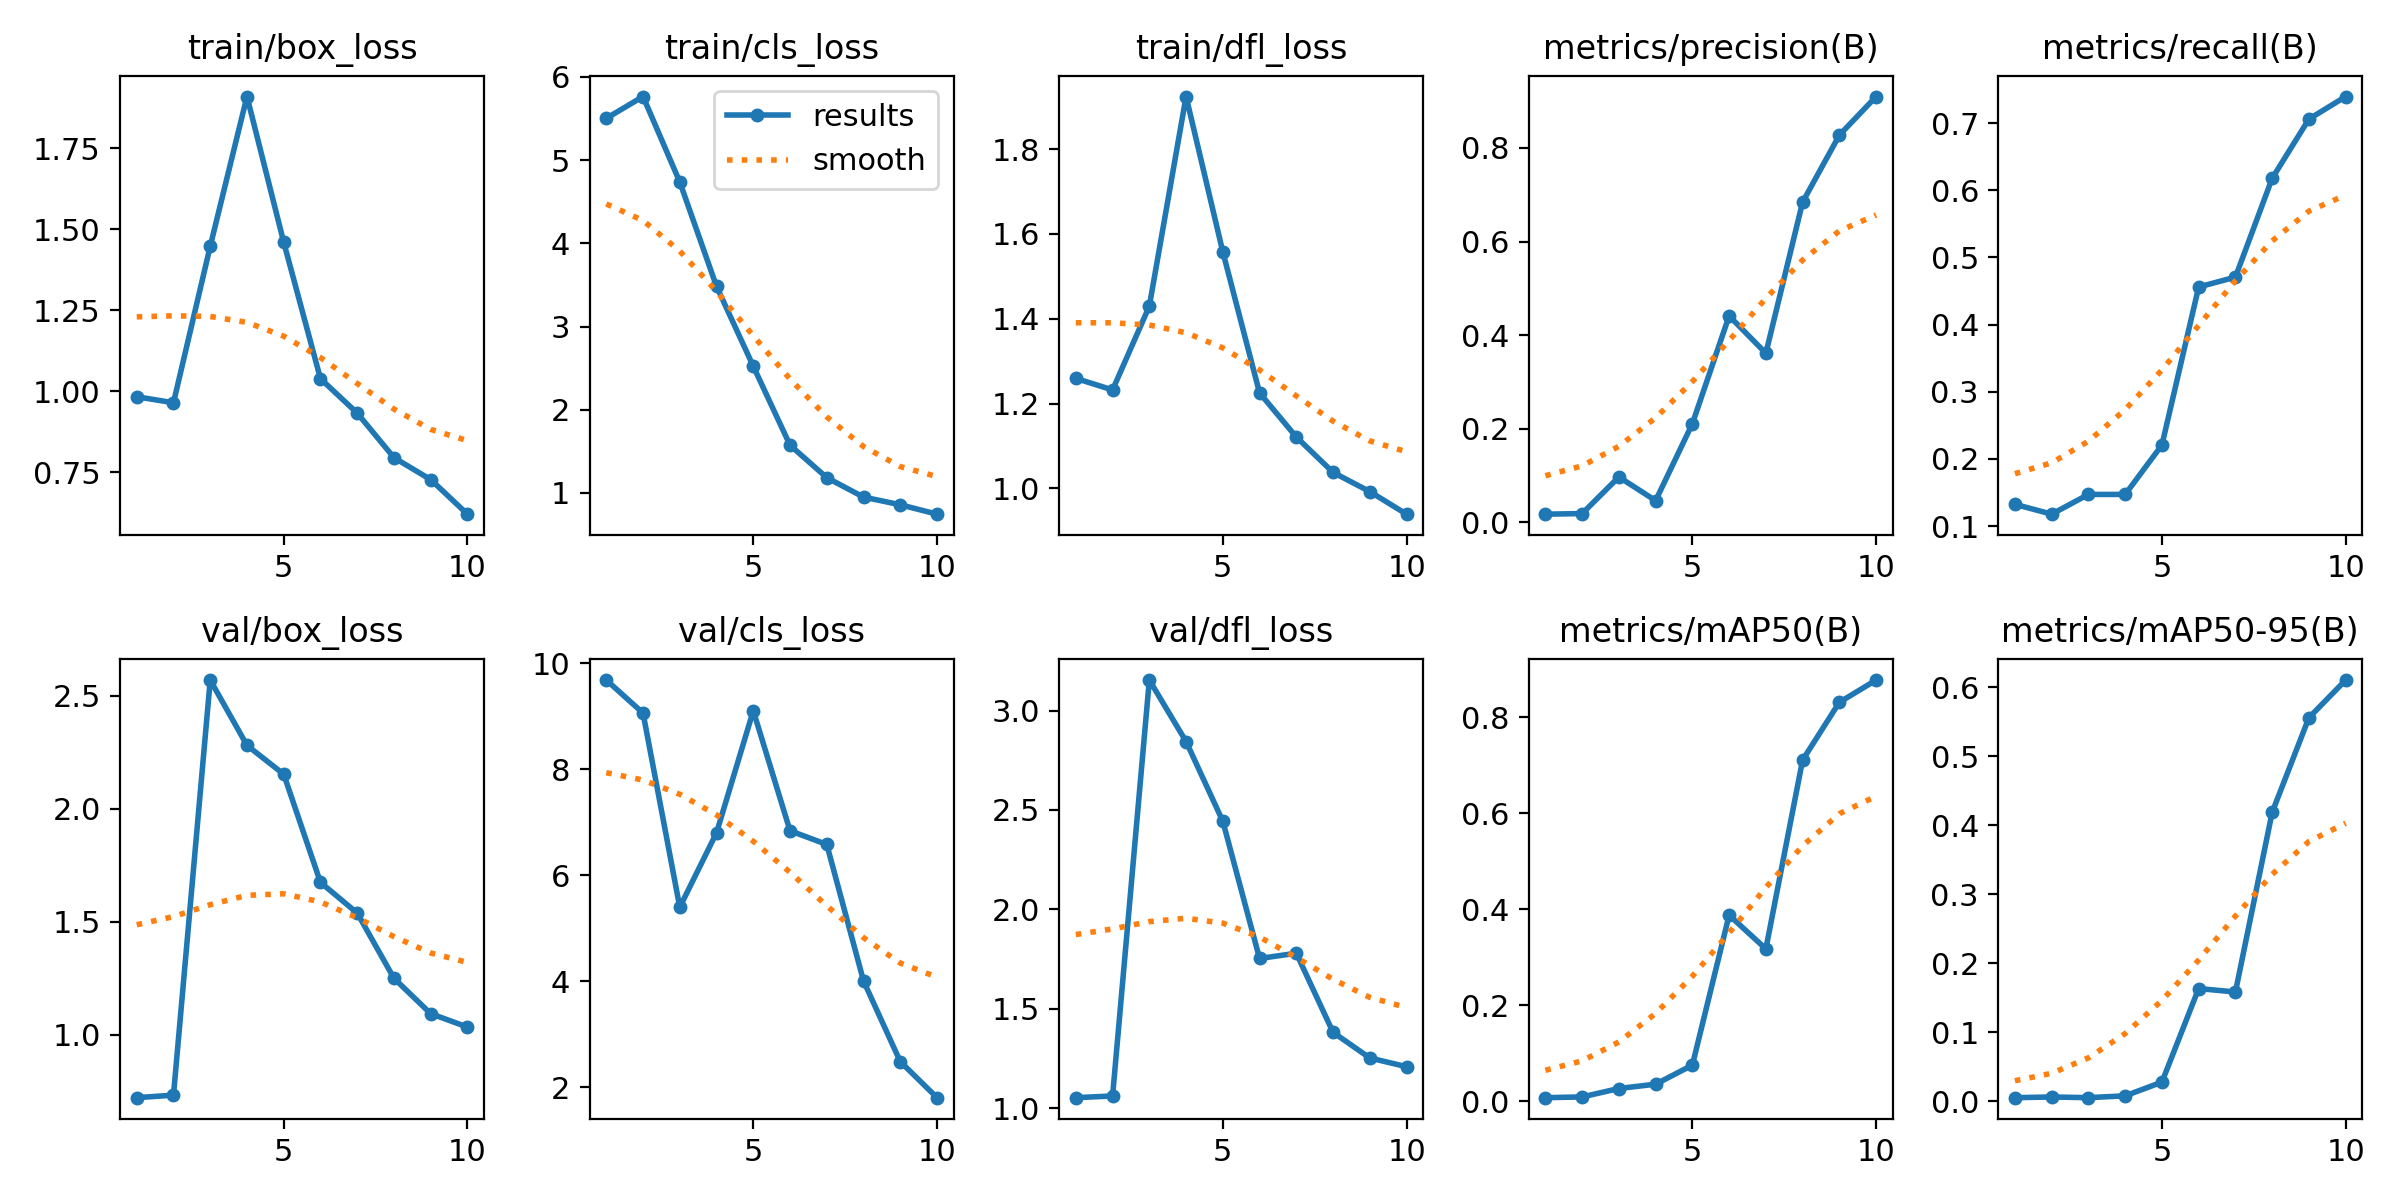

confusion_matrix_normalized.png


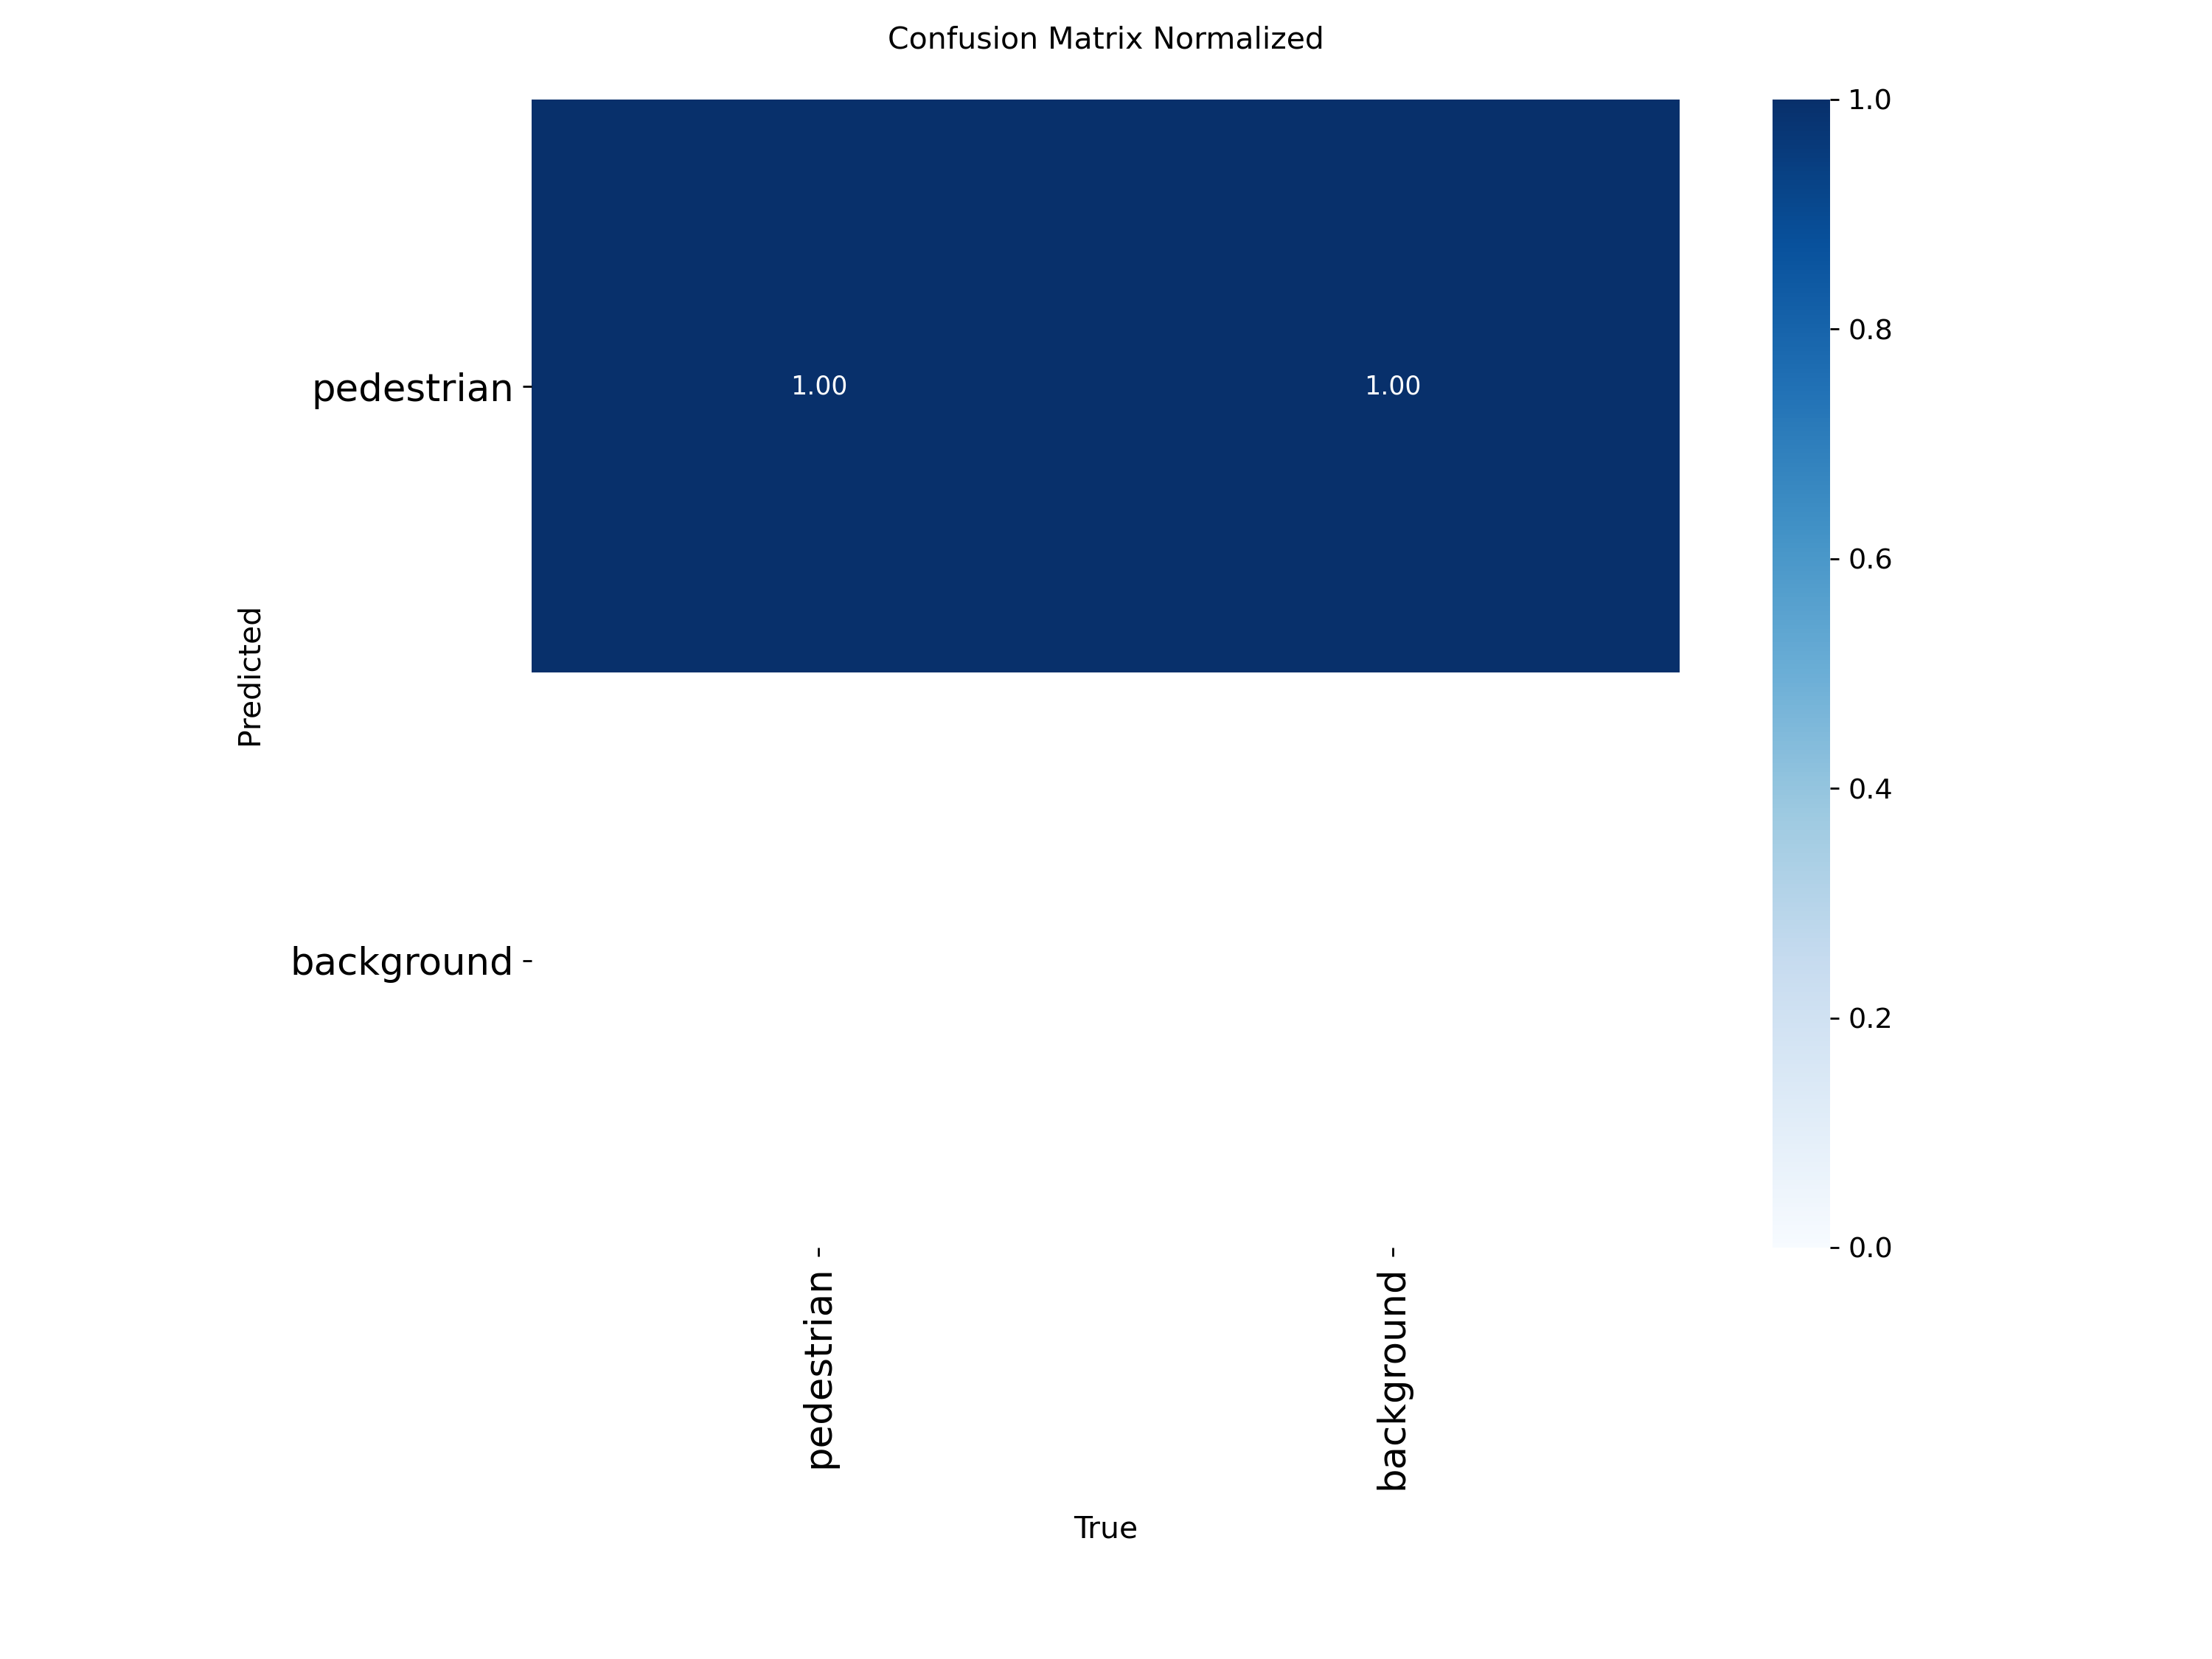

In [22]:
from IPython.display import Image as NotebookImage, display

for filename in ('results.png', 'PR_curve.png', 'confusion_matrix_normalized.png'):
    file_path = run_dir / filename
    if file_path.exists():
        print(filename)
        display(NotebookImage(filename=str(file_path)))

## 5. Test on unseen images

The test split was never used to update model weights. Compare the predicted boxes with the reference boxes for the same image.

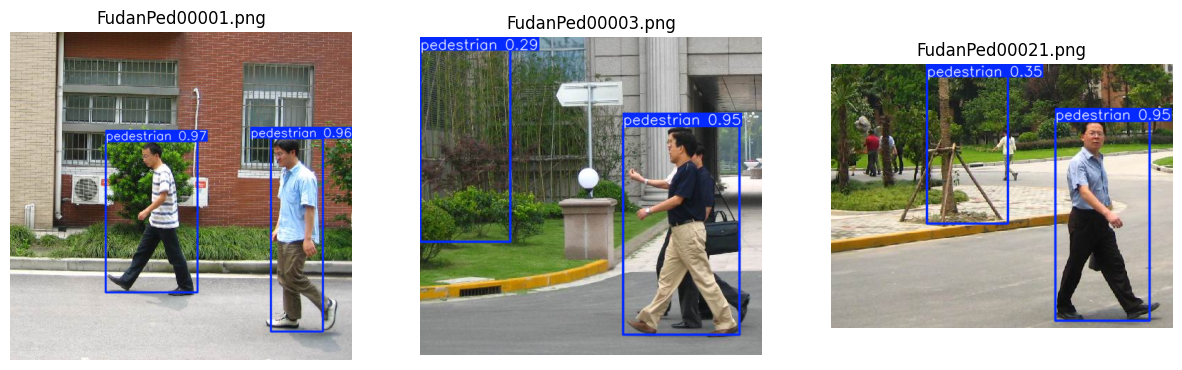

In [23]:
test_images = sorted((dataset_root / 'test' / 'images').glob('*.png'))[:3]
prediction_results = best_model.predict(
    source=[str(path) for path in test_images],
    imgsz=512,
    conf=0.25,
    device=0,
    verbose=False,
)

figure, axes = plt.subplots(1, len(prediction_results), figsize=(5 * len(prediction_results), 5))
if len(prediction_results) == 1:
    axes = [axes]
for axes_item, prediction, image_path in zip(axes, prediction_results, test_images):
    axes_item.imshow(prediction.plot()[:, :, ::-1])
    axes_item.set_title(image_path.name)
    axes_item.axis('off')
plt.show()

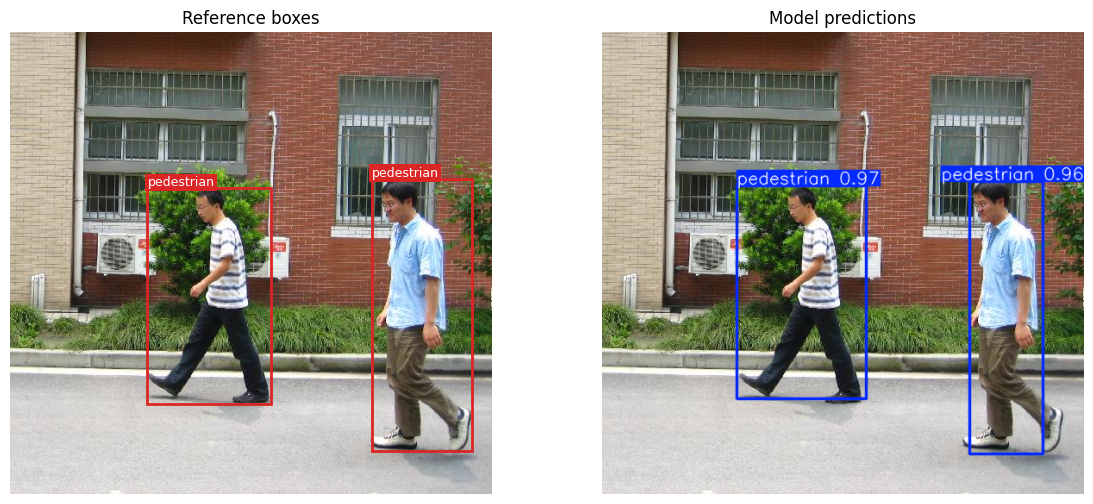

In [24]:
ground_truth_image, ground_truth_classes, ground_truth_boxes, ground_truth_path = dd.load_yolo_sample(
    dataset_root, 'test', index=0
)
first_prediction = prediction_results[0].plot()[:, :, ::-1]

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
dd.plot_yolo_sample(axes[0], ground_truth_image, ground_truth_classes, ground_truth_boxes)
axes[0].set_title('Reference boxes')
axes[1].imshow(first_prediction)
axes[1].set_title('Model predictions')
axes[1].axis('off')
plt.show()

## Check your understanding

1. Why is mAP across IoU thresholds usually lower than mAP at IoU 0.50?
2. Choose one test image. Compare its prediction with the reference boxes. Identify one correct detection; if you see a missed or extra box, describe a likely visual reason.
3. Why must test images remain outside both augmentation and training?
4. Name one training-data improvement you would try before changing the model architecture.

###1.
mAP across multiple IoU thresholds (e.g., mAP@0.50:0.95) calculates the average performance of the model across several increasingly strict overlap requirements. While an IoU of 0.50 only requires a loose, basic overlap between the predicted and ground truth boxes, higher thresholds (like 0.75 or 0.90) demand near-perfect spatial alignment. Because it is significantly harder for a model to achieve high precision at these stricter thresholds, the overall average across all of them naturally drops compared to the lenient mAP@0.50 score.
###2.
In the selected test image, the model correctly detects the main pedestrian in the foreground with a tight bounding box and high confidence. However, it produces a missed detection (false negative) for a second pedestrian partially hidden in the background. The likely visual reason for this is severe occlusion and low lighting contrast, which causes the hidden figure to blend into the background and lack the distinct edge features the model relies on for recognition.
###3.
Test images must remain completely separate from training and augmentation to prevent data leakage and ensure an unbiased, realistic evaluation. If the model is exposed to these images or their augmented variations during the training phase, it will simply memorize their specific features rather than learning to generalize. Keeping the test set strictly isolated guarantees that the final performance metrics accurately reflect how the model will perform on truly unseen, real-world data.
###4.
Before changing the model architecture, I would improve the training data by implementing more advanced augmentation techniques, such as Mosaic or MixUp. These methods combine multiple images or random patches into a single training sample, forcing the model to learn more robust, context-independent features and improving its ability to detect small or partially occluded objects. Additionally, manually auditing and correcting any noisy or inaccurate bounding box annotations in the current dataset would directly boost the quality of the model's learning.


## 6. Test the detector on a new scene

Choose one new scene containing at least one pedestrian: either one image or a short 5–15 second video (MP4 is recommended). Do not use an image from the Penn-Fudan dataset. Put exactly one file (JPG, JPEG, PNG, MP4, MOV, or AVI) in `work/student_input/`. In Google Colab, the next cell opens an upload dialog if the folder is empty; in VS Code, copy the file into that folder.

The next cell runs the trained model at confidence thresholds 0.25 and 0.50, so you can see how the threshold changes the predicted boxes. It displays annotated images and saves annotated videos in `work/student_runs/`. If you run the task again, leave only one supported input file in `work/student_input/`.

Saving my_image.jpg to my_image.jpg
Results saved to /content/work/student_runs/conf_25
Confidence 0.25: /content/work/student_runs/conf_25


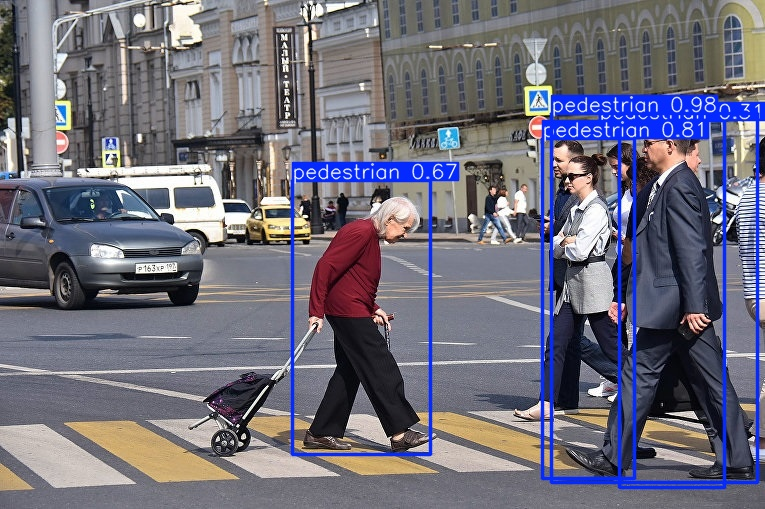

Results saved to /content/work/student_runs/conf_50
Confidence 0.50: /content/work/student_runs/conf_50


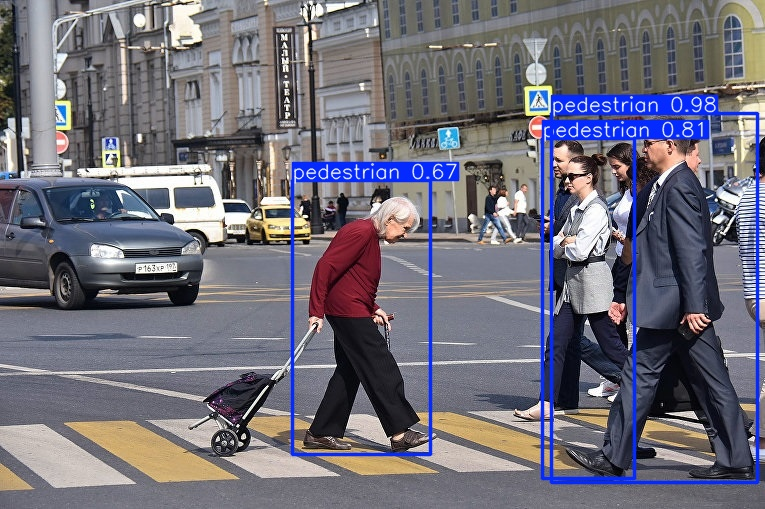

In [25]:
from IPython.display import Image as NotebookImage, display

student_input_dir = workspace / 'student_input'
student_input_dir.mkdir(exist_ok=True)
image_suffixes = {'.jpg', '.jpeg', '.png'}
video_suffixes = {'.mp4', '.mov', '.avi'}
supported_suffixes = image_suffixes | video_suffixes
student_sources = sorted(
    path for path in student_input_dir.iterdir()
    if path.is_file() and path.suffix.lower() in supported_suffixes
)
if not student_sources and 'google.colab' in sys.modules:
    from google.colab import files

    uploaded_files = files.upload()
    for filename, contents in uploaded_files.items():
        (student_input_dir / Path(filename).name).write_bytes(contents)
    student_sources = sorted(
        path for path in student_input_dir.iterdir()
        if path.is_file() and path.suffix.lower() in supported_suffixes
    )
if len(student_sources) != 1:
    print(
        f'Add exactly one image or video to {student_input_dir} before running this task. '
        f'Found {len(student_sources)} supported files.'
    )
else:
    student_source = student_sources[0]
    is_video = student_source.suffix.lower() in video_suffixes
    student_run_root = workspace / 'student_runs'
    student_run_root.mkdir(exist_ok=True)

    for confidence in (0.25, 0.50):
        run_name = f'conf_{int(confidence * 100):02d}'
        output_dir = student_run_root / run_name
        predictions = best_model.predict(
            source=str(student_source),
            imgsz=512,
            conf=confidence,
            device=0,
            save=True,
            project=str(student_run_root),
            name=run_name,
            exist_ok=True,
            stream=is_video,
            verbose=False,
        )
        if is_video:
            for _ in predictions:
                pass

        print(f'Confidence {confidence:.2f}: {output_dir}')
        if not is_video:
            saved_images = sorted(
                path for path in output_dir.iterdir()
                if path.suffix.lower() in image_suffixes
            )
            if saved_images:
                display(NotebookImage(filename=str(saved_images[0])))